# **BlinkIT Grocery Sales Analysis**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
df = pd.read_excel("/content/drive/MyDrive/Sapphire IQ/BlinkIT Grocery Data.xlsx")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [29]:
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


# **Objective 1 — Understand the business**

In [31]:
df.sample(10)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
7560,Regular,FDP31,Fruits and Vegetables,2017,OUT035,Tier 2,Small,Supermarket Type1,0.161474,21.100,62.9168,4.0
25,Low Fat,FDB53,Frozen Foods,2020,OUT017,Tier 2,Medium,Supermarket Type1,0.140241,13.350,150.2392,5.0
3608,Low Fat,FDA49,Canned,2011,OUT010,Tier 3,Medium,Grocery Store,0.108666,19.700,86.4198,4.0
7130,Low Fat,FDH34,Snack Foods,2020,OUT017,Tier 2,High,Supermarket Type1,0.031271,8.630,186.0582,4.0
103,Low Fat,NCR54,Household,2018,OUT019,Tier 1,Small,Grocery Store,0.158563,12.600,194.7110,5.0
1229,Low Fat,FDO25,Canned,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.127968,6.300,209.6270,4.4
5111,Low Fat,FDZ40,Frozen Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.039988,12.600,55.7298,3.3
4504,Low Fat,FDL33,Snack Foods,2017,OUT035,Tier 2,Small,Supermarket Type1,0.000000,7.235,197.2452,3.7
8395,Low Fat,FDK09,Snack Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.091319,12.600,230.7352,4.0
964,Low Fat,NCK54,Household,2020,OUT017,Tier 2,Medium,Supermarket Type1,0.000000,12.150,117.8150,4.4


In [32]:
print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Total sales:", df["Sales"].sum())
print("Average sales:", df["Sales"].mean())
print("Average rating:", df["Rating"].mean())

Total rows: 8523
Total columns: 12
Total sales: 1201681.4928
Average sales: 140.99278338613163
Average rating: 3.965857092573038


In [36]:
df['Item Type'].unique()

array(['Fruits and Vegetables', 'Health and Hygiene', 'Frozen Foods',
       'Canned', 'Soft Drinks', 'Household', 'Snack Foods', 'Meat',
       'Breads', 'Hard Drinks', 'Others', 'Dairy', 'Breakfast',
       'Baking Goods', 'Seafood', 'Starchy Foods'], dtype=object)

In [37]:
df['Item Type'].nunique()

16

In [9]:
df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,8523.000000,8523.000000,7060.000000,8523.000000,8523.000000
mean,2016.450546,0.066132,12.857645,140.992783,3.965857
std,3.189396,0.051598,4.643456,62.275067,0.605651
min,2011.000000,0.000000,4.555000,31.290000,1.000000
25%,2014.000000,0.026989,8.773750,93.826500,4.000000
50%,2016.000000,0.053931,12.600000,143.012800,4.000000
75%,2018.000000,0.094585,16.850000,185.643700,4.200000
max,2022.000000,0.328391,21.350000,266.888400,5.000000


# **Objective 2 — Clean the data**

In [53]:
df.isnull().sum()

,0
Item Fat Content,0
Item Identifier,0
Item Type,0
Outlet Establishment Year,0
Outlet Identifier,0
Outlet Location Type,0
Outlet Size,0
Outlet Type,0
Item Visibility,0
Item Weight,0


In [54]:
df.isnull().sum()/len(df)*100 #Missing valuen in terms of percentage

,0
Item Fat Content,0.0
Item Identifier,0.0
Item Type,0.0
Outlet Establishment Year,0.0
Outlet Identifier,0.0
Outlet Location Type,0.0
Outlet Size,0.0
Outlet Type,0.0
Item Visibility,0.0
Item Weight,0.0


In [40]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
# If less than 5% missing value present then we remove the missing

In [41]:
df = df.drop_duplicates()

In [57]:
df["Item Fat Content"].unique()

array(['Regular', 'Low Fat'], dtype=object)

In [11]:
df["Item Fat Content"] = df["Item Fat Content"].replace({
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "reg": "Regular",
    "regular": "Regular"
})

df["Item Fat Content"].value_counts()


,count
Item Fat Content,
Low Fat,5517
Regular,3006


## **Objective 3 — Analyze sales**

In [49]:
print("Total Sales",df["Sales"].sum())
print("Average Sales",df["Sales"].mean())
print("Max Sales",df["Sales"].max())
print("Min Sales",df["Sales"].min())
print("Total Rating",df["Rating"].sum())
print("Average Rating",df["Rating"].mean())
print("Max Rating",df["Rating"].max())
print("Min Rating",df["Rating"].min())

Total Sales 1201681.4928
Average Sales 140.99278338613163
Max Sales 266.8884
Min Sales 31.29
Total Rating 33801.0
Average Rating 3.965857092573038
Max Rating 5.0
Min Rating 1.0


In [13]:
category_sales = df.groupby("Item Type")["Sales"].sum()

category_sales.sort_values(ascending=False)


,Sales
Item Type,
Fruits and Vegetables,178124.0810
Snack Foods,175433.9224
Household,135976.5254
Frozen Foods,118558.8814
Dairy,101276.4616
Canned,90706.7290
Baking Goods,81894.7364
Health and Hygiene,68025.8388
Meat,59449.8638


## **Visualize category sales**

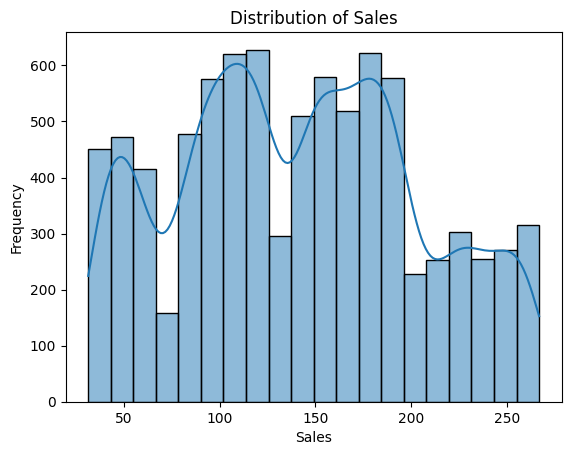

In [51]:
sns.histplot(data=df, x="Sales", bins=20, kde=True)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

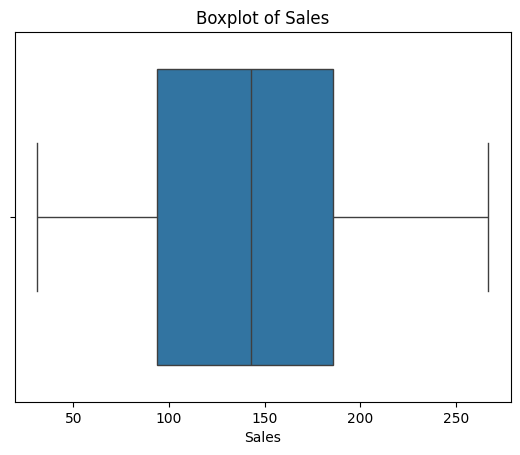

In [55]:
sns.boxplot(data=df, x="Sales")

plt.title("Boxplot of Sales")
plt.xlabel("Sales")
plt.show()

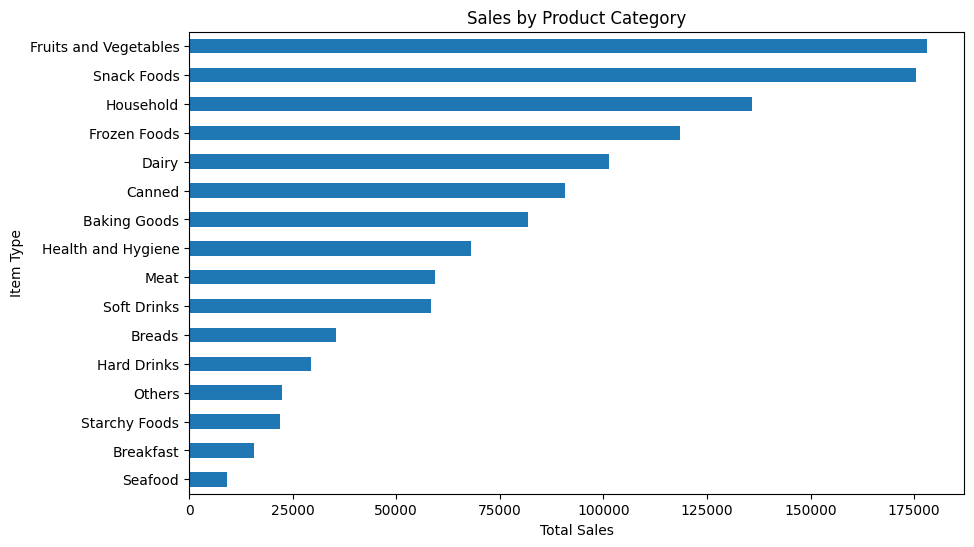

In [14]:
category_sales.sort_values().plot(
    kind="barh", figsize=(10, 6)
)

plt.title("Sales by Product Category")
plt.xlabel("Total Sales")
plt.show()


## **Sales by outlet type**

In [59]:
sale_item = df.groupby("Item Type")["Sales"].sum().sort_values(ascending=False)
print(sale_item)

Item Type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9224
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4616
Canned                    90706.7290
Baking Goods              81894.7364
Health and Hygiene        68025.8388
Meat                      59449.8638
Soft Drinks               58514.1670
Breads                    35379.1198
Hard Drinks               29334.6806
Others                    22451.8916
Starchy Foods             21880.0274
Breakfast                 15596.6966
Seafood                    9077.8700
Name: Sales, dtype: float64


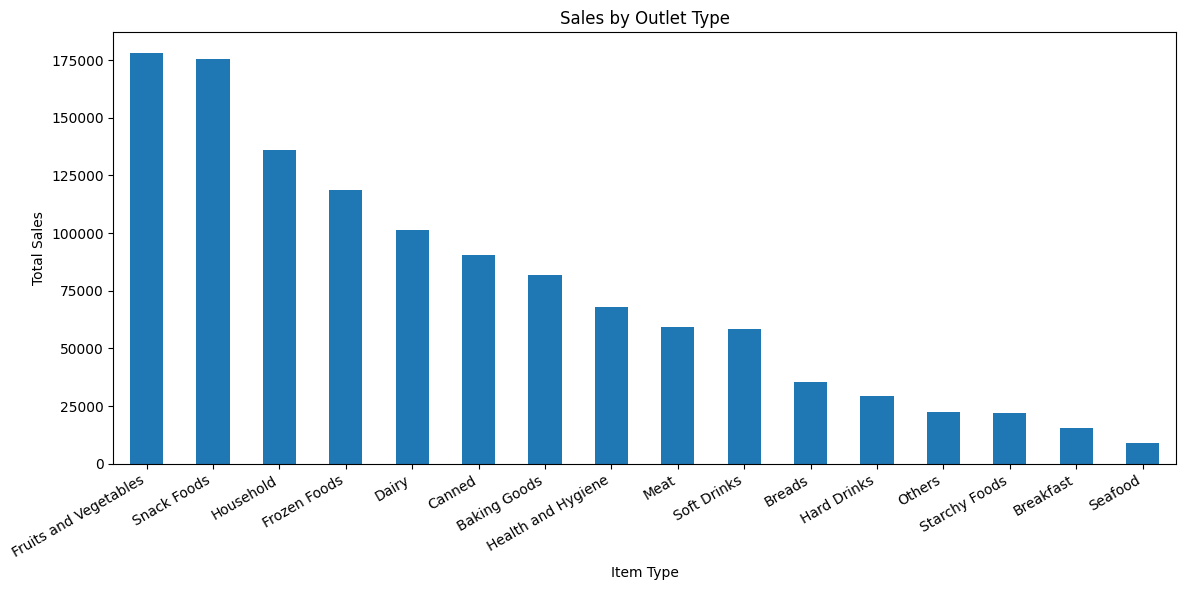

In [63]:
plt.figure(figsize=(12, 6))

sale_item.plot(kind="bar")
plt.title("Sales by Outlet Type")
plt.ylabel("Total Sales")
plt.xlabel("Item Type")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.show()


In [15]:
outlet_sales = df.groupby("Outlet Type")["Sales"].sum()

outlet_sales.sort_values(ascending=False)


,Sales
Outlet Type,
Supermarket Type1,787549.8928
Grocery Store,151939.1490
Supermarket Type2,131477.7764
Supermarket Type3,130714.6746


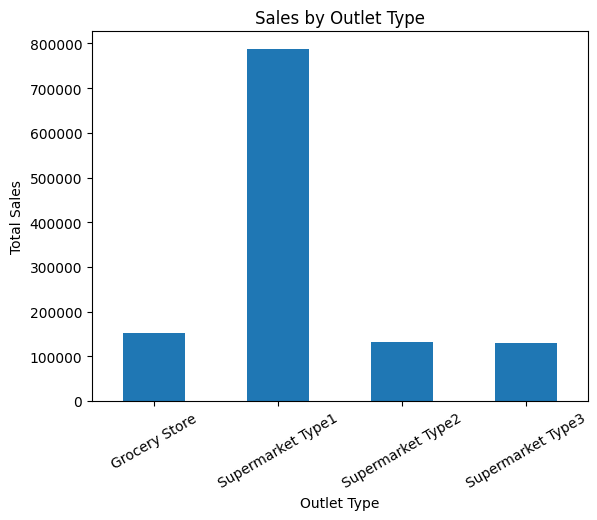

In [16]:
outlet_sales.plot(kind="bar")

plt.title("Sales by Outlet Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.show()


## **Sales by location**

In [17]:
location_sales = df.groupby(
    "Outlet Location Type"
)["Sales"].sum()

location_sales


,Sales
Outlet Location Type,
Tier 1,336397.8120
Tier 2,393150.6476
Tier 3,472133.0332


## **Sales by fat content**

In [18]:
size_sales = df.groupby("Outlet Size")["Sales"].sum()

size_sales


,Sales
Outlet Size,
High,248991.5860
Medium,507895.7364
Small,444794.1704


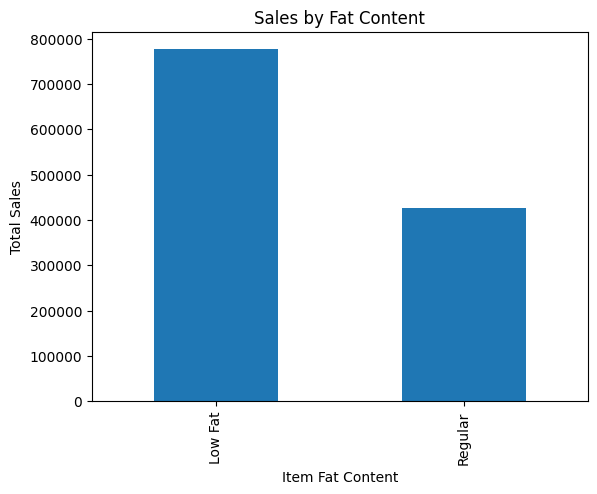

In [19]:
fat_sales = df.groupby("Item Fat Content")["Sales"].sum()

fat_sales.plot(kind="bar")

plt.title("Sales by Fat Content")
plt.ylabel("Total Sales")
plt.show()


## **Top 10 products by total sales**

In [20]:
top_products = df.groupby(
    "Item Identifier"
)["Sales"].sum().nlargest(10)

top_products


,Sales
Item Identifier,
FDU12,2371.0112
FDT07,2306.8970
NCQ06,2294.7126
FDL58,2111.6544
NCB31,2104.7280
FDX31,2104.4622
FDF05,2103.1280
FDR59,2096.5752
FDP28,2087.8488


In [21]:
print("Average rating:", df["Rating"].mean())

df.groupby("Item Type")["Rating"].mean().sort_values(
    ascending=False
)


Average rating: 3.965857092573038


,Rating
Item Type,
Meat,4.023059
Household,3.998681
Canned,3.994299
Health and Hygiene,3.986154
Baking Goods,3.983025
Frozen Foods,3.971145
Dairy,3.965836
Seafood,3.959375
Fruits and Vegetables,3.956169


## **Relationship between visibility and sales**

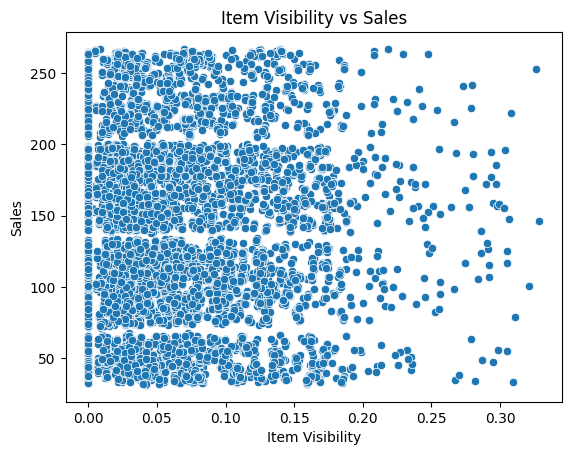

In [22]:
sns.scatterplot(
    data=df,
    x="Item Visibility",
    y="Sales"
)

plt.title("Item Visibility vs Sales")
plt.show()


## **Correlation heatmap**

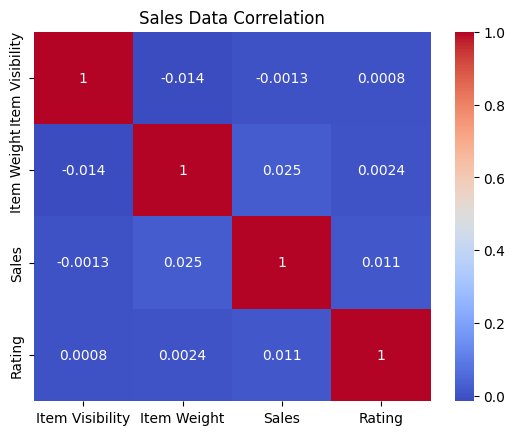

In [23]:
sns.heatmap(
    df[["Item Visibility", "Item Weight",
        "Sales", "Rating"]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Sales Data Correlation")
plt.show()


# **Objective 4 — Business insights**

In [24]:
print("Top category:")
print(category_sales.idxmax())

print("Highest category sales:")
print(category_sales.max())


Top category:
Fruits and Vegetables
Highest category sales:
178124.081


In [25]:
print("Top outlet type:")
print(outlet_sales.idxmax())

print("Highest outlet sales:")
print(outlet_sales.max())


Top outlet type:
Supermarket Type1
Highest outlet sales:
787549.8928


In [26]:
print("BLINKIT SALES REPORT")
print("--------------------")

print("Total sales:", round(df["Sales"].sum(), 2))
print("Average sales:", round(df["Sales"].mean(), 2))
print("Average rating:", round(df["Rating"].mean(), 2))

print("Best category:", category_sales.idxmax())
print("Best outlet:", outlet_sales.idxmax())
print("Best location:", location_sales.idxmax())


BLINKIT SALES REPORT
--------------------
Total sales: 1201681.49
Average sales: 140.99
Average rating: 3.97
Best category: Fruits and Vegetables
Best outlet: Supermarket Type1
Best location: Tier 3


In [27]:

columns = ["Sales", "Item Weight", "Item Visibility", "Rating"]

for col in columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr

    count = ((df[col] < low) | (df[col] > high)).sum()

    print(col, "potential outliers:", count)


Sales potential outliers: 0
Item Weight potential outliers: 0
Item Visibility potential outliers: 144
Rating potential outliers: 1931


In [28]:
print("BUSINESS RECOMMENDATIONS")
print("1. Monitor stock availability in top-selling categories.")
print("2. Study the factors behind high-performing outlets.")
print("3. Investigate low-performing outlet groups.")
print("4. Review product visibility and customer ratings.")
print("5. Use sales trends to support inventory planning.")


BUSINESS RECOMMENDATIONS
1. Monitor stock availability in top-selling categories.
2. Study the factors behind high-performing outlets.
3. Investigate low-performing outlet groups.
4. Review product visibility and customer ratings.
5. Use sales trends to support inventory planning.
